# Tag 6 - Modell festlegen

## Ladezelle

In [22]:
import sqlite3
import pandas as pd
from sklearn.model_selection import train_test_split

SQL_PATH = "../data/interim/projekt.sqlite"

con = sqlite3.connect(SQL_PATH)
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)
blockgroups = pd.read_sql("SELECT * FROM blockgruppen", con)
X = blockgroups.drop(columns=["MedHouseVal"])
y = blockgroups["MedHouseVal"]

print(blockgroups.shape)
# -> (20640, 9)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Trainingszeilen:", len(X_train))
print("Testzeilen:", len(X_test))

(20640, 9)
Trainingszeilen: 16512
Testzeilen: 4128


## Log-Transformation

In [23]:
import numpy as np

log_spalten = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

X_train_log = X_train.copy()
X_test_log = X_test.copy()

for spalte in log_spalten:
    X_train_log[spalte] = np.log(X_train_log[spalte])
    X_test_log[spalte] = np.log(X_test_log[spalte])

display(X_test_log[log_spalten].head())

,AveRooms,AveBedrms,Population,AveOccup
20046,1.433226,0.022039,7.238497,1.355174
3024,1.617284,0.176884,7.355641,0.985740
15663,1.380567,0.170483,7.177782,0.307729
20484,1.818667,0.020001,7.441320,1.236763
9814,1.703473,0.027652,6.968850,0.909727


## LinearRegression

In [24]:
from sklearn.linear_model import LinearRegression

modell = LinearRegression()
modell.fit(X_train_log, y_train)

y_pred = modell.predict(X_test_log)

print("Anzahl Vorhersagen:", len(y_pred))

Anzahl Vorhersagen: 4128


## Residuum

In [25]:
evaluation = X_test.copy()

evaluation["Ist"] = y_test
evaluation["Prognose"] = y_pred
evaluation["Residuum"] = evaluation["Ist"] - evaluation["Prognose"]

display(evaluation.head())

# ----------------------------------------------
# Residuum = tatsächlicher Wert - Vorhersage
# Positiv: Modell unterschätzt den Hauswert
# Negativ: Modell überschätzt den Hauswert
# ----------------------------------------------

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Ist,Prognose,Residuum
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700,0.441511,0.035489
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800,1.857067,-1.399067
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001,3.426003,1.574007
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600,2.654853,-0.468853
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000,2.665105,0.114895


## Fehler nach Einkommensgruppen

In [26]:
evaluation["Einkommensgruppe"] = pd.qcut(
    evaluation["MedInc"],
    q=4,
    labels=["Niedrig", "Mittel-niedrig", "Mittel-hoch", "Hoch"]
)
# -> .qcut teilt die Daten in Quantile auf

fehler_einkommen = evaluation.groupby(
    "Einkommensgruppe", observed=True
).agg(
    Anzahl=("Residuum", "size"),
    Mittleres_Residuum=("Residuum", "mean"),
    MAE=("Residuum", lambda x: x.abs().mean())
).reset_index()
# groupby() = Daten in Gruppen aufteilen
# agg()     = Kennzahlen für jede Gruppe berechnen
# lambda    = Eigene kleine Berechnungsfunktion definieren
# reset_index() macht den Gruppenindex wieder zu einer normalen Spalte.

display(fehler_einkommen.round(4))

,Einkommensgruppe,Anzahl,Mittleres_Residuum,MAE
0,Niedrig,1032,0.0304,0.4110
1,Mittel-niedrig,1039,-0.0191,0.4682
2,Mittel-hoch,1025,-0.0174,0.5237
3,Hoch,1032,0.0322,0.5589


### Fehleranalyse nach Einkommensgruppen

Der MAE steigt mit zunehmendem Einkommen von 0,4110 auf 0,5589 (ca. +36 %). Das Modell ist bei einkommensstärkeren Wohngebieten somit ungenauer.

Die mittleren Residuen liegen nahe null, da sich Über- und Unterschätzungen teilweise ausgleichen.

## Gedeckelte Zielwerte

In [27]:
max_wert = blockgroups["MedHouseVal"].max()

evaluation["Gedeckelt"] = evaluation["Ist"] == max_wert

fehler_deckelung = evaluation.groupby("Gedeckelt").agg(
    Anzahl=("Residuum", "size"),
    Mittleres_Residuum=("Residuum", "mean"),
    MAE=("Residuum", lambda x: x.abs().mean())
).reset_index()

display(fehler_deckelung.round(4))

,Gedeckelt,Anzahl,Mittleres_Residuum,MAE
0,False,3949,-0.0378,0.4513
1,True,179,0.9851,1.3522


### Fehleranalyse bei gedeckelten Zielwerten

Bei den 179 gedeckelten Testwerten liegt der MAE mit 1,3522 etwa dreimal so hoch wie bei den übrigen Werten (0,4513).

Das positive mittlere Residuum (+0,9851) zeigt eine deutliche Unterschätzung. Da die tatsächlichen Hauswerte über der Deckelungsgrenze liegen können, lässt sich der Einfluss der Deckelung nicht eindeutig vom Modellfehler trennen.

# Tag 7 - Fehler nach Regionen und Einsatzgruppen

## Fehler-Heatmap

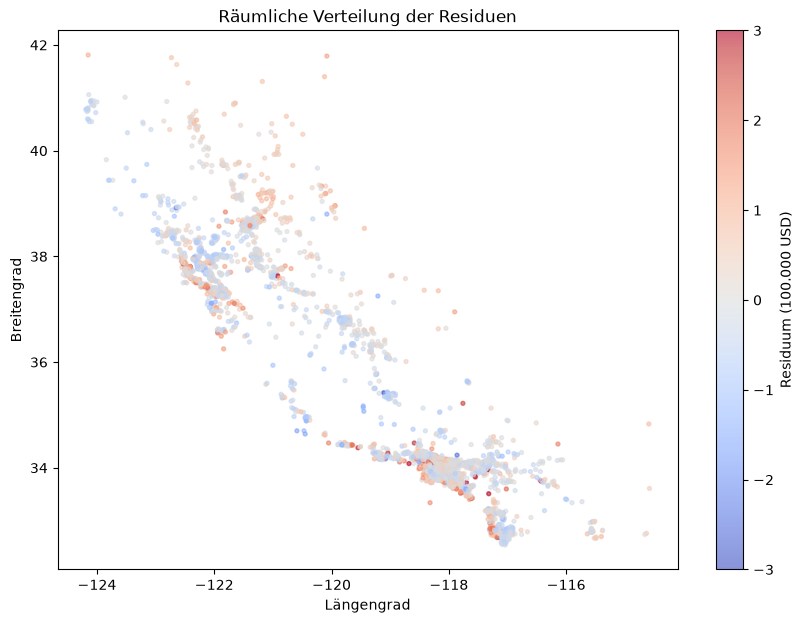

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    evaluation["Longitude"],
    evaluation["Latitude"],
    c=evaluation["Residuum"],
    cmap="coolwarm",
    s=8,
    alpha=0.6,
    vmin=-3,
    vmax=3
)

plt.colorbar(label="Residuum (100.000 USD)")
plt.xlabel("Längengrad")
plt.ylabel("Breitengrad")
plt.title("Räumliche Verteilung der Residuen")
plt.show()

## Fehler nach Region

In [29]:
regionen = {
    "San Francisco Bay Area": (
        (evaluation["Latitude"].between(37.0, 38.5)) &
        (evaluation["Longitude"].between(-123.0, -121.5))
    ),
    "Los Angeles": (
        (evaluation["Latitude"].between(33.5, 34.5)) &
        (evaluation["Longitude"].between(-119.0, -117.5))
    ),
    "Central Valley": (
        (evaluation["Latitude"].between(35.0, 38.0)) &
        (evaluation["Longitude"].between(-121.5, -118.5))
    )
}
# between() prüft, ob ein Wert innerhalb eines bestimmten Bereichs liegt.

ergebnisse_regionen = []

for name, maske in regionen.items():
    daten = evaluation.loc[maske, "Residuum"]

    ergebnisse_regionen.append({
        "Region": name,
        "Anzahl": len(daten),
        "Mittleres_Residuum": daten.mean(),
        "MAE": daten.abs().mean()
    })

vergleich_regionen = pd.DataFrame(ergebnisse_regionen)

display(vergleich_regionen.round(4))

,Region,Anzahl,Mittleres_Residuum,MAE
0,San Francisco Bay Area,868,0.0189,0.5495
1,Los Angeles,1583,0.1009,0.4906
2,Central Valley,445,-0.2500,0.4369


### Fehleranalyse

Die San Francisco Bay Area weist mit 0,5495 den höchsten MAE auf, gefolgt von Los Angeles (0,4906) und Central Valley (0,4369). Im Central Valley überschätzt das Modell die Hauswerte durchschnittlich um 25.000 USD, während es sie in Los Angeles um etwa 10.090 USD unterschätzt.

## Einsatzgrenzen des Modells

Das Modell eignet sich für grobe Hauswertschätzungen, wobei selbst in der niedrigsten Einkommensgruppe ein durchschnittlicher absoluter Fehler von 41.100 USD auftritt.

Bei hohen Einkommen steigt dieser Fehler auf 55.890 USD, weshalb die Schätzungen dort weniger zuverlässig sind.

Besondere Vorsicht gilt für gedeckelte Hauswerte: Hier beträgt der MAE 135.220 $ und ist damit etwa dreimal so hoch wie bei nicht gedeckelten Werten.

Regional ist die Schätzung in der San Francisco Bay Area mit einem MAE von 54.950 USD besonders ungenau.

Im Central Valley überschätzt das Modell die Hauswerte durchschnittlich um 25.000 USD, weshalb regionale Verzerrungen berücksichtigt werden müssen.

Aus diesen Ergebnissen lassen sich weder exakte Immobilienpreise noch tatsächliche Werte oberhalb der Deckelungsgrenze von 500.001 USD ableiten.